In [1]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import datetime

In [2]:
%matplotlib inline
pd.set_option("display.max_columns", 100)
sns.set(color_codes=True)

---
## DATA LOADING AND CLEANING
---

In [3]:
DATA_DIR = "./"
PRODUCT_DATA = os.path.join(DATA_DIR, "product_data.csv")
TRANSACTIONS_DATA = os.path.join(DATA_DIR, "transactions_data.csv")

In [4]:
product_data = pd.read_csv(PRODUCT_DATA)
transaction_data = pd.read_csv(TRANSACTIONS_DATA)

In [5]:
transaction_data.head(3)

,transaction_id,product_id,purchased_quantity,transaction_date,unit_product_price,customer_id
0,0,2858,6,05/01/2012 08:26,2.55,447
1,0,2240,6,05/01/2012 08:26,3.39,447
2,0,2685,8,05/01/2012 08:26,2.75,447


In [6]:
product_data.head(3)

,product_id,color
0,2523,black
1,2938,yellow
2,1684,white


In [7]:
transaction_data[transaction_data.duplicated()].sort_values(list(transaction_data.columns))

,transaction_id,product_id,purchased_quantity,transaction_date,unit_product_price,customer_id
171,13,745,1,05/01/2012 12:23,2.95,456
150,13,1512,1,05/01/2012 12:23,2.10,456
178,13,1512,1,05/01/2012 12:23,2.10,456
154,13,1580,6,05/01/2012 12:23,0.85,456
584,46,171,1,06/01/2012 19:59,0.65,186
...,...,...,...,...,...,...
1704,2097,1610,-12,14/01/2012 14:03,1.25,255
1705,2097,1610,-12,14/01/2012 14:03,1.25,255
5986,2140,2279,-1,16/03/2012 14:38,4.95,447
5994,2140,2279,-1,16/03/2012 14:38,4.95,447


In [8]:
product_data[product_data.duplicated()].sort_values(list(product_data.columns))

,product_id,color


In [9]:
# Duplicated rows dropped
transaction_data = transaction_data.drop_duplicates()

---
## DATA EXPLORATION
---

In [10]:
data = pd.merge(transaction_data, product_data, on="product_id")
data.head()

,transaction_id,product_id,purchased_quantity,transaction_date,unit_product_price,customer_id,color
0,0,2858,6,05/01/2012 08:26,2.55,447,blue
1,0,2240,6,05/01/2012 08:26,3.39,447,red
2,0,2685,8,05/01/2012 08:26,2.75,447,black
3,0,2667,6,05/01/2012 08:26,3.39,447,blue
4,0,2666,6,05/01/2012 08:26,3.39,447,black


In [11]:
data.groupby("color")["purchased_quantity"].sum().sort_values(ascending=False)

color
black     229234
white     160641
blue       93829
red        78333
green      56712
yellow     33132
Name: purchased_quantity, dtype: int64

Black items have been purchased the most in terms of total number of items sold.

---
## FEATURE ENGINEERING
---

Our goal is to create a model that predicts if a customer will purchase again, starting the 1st of October 2012. Let's first filter the data to the pre-October-2012 period.

In [12]:
data["transaction_date"] = pd.to_datetime(data["transaction_date"], errors="coerce")
start_date = pd.to_datetime("01/10/2012", format="%d/%m/%Y")
train_data = data[data["transaction_date"] < start_date]
train_data

,transaction_id,product_id,purchased_quantity,transaction_date,unit_product_price,customer_id,color
0,0,2858,6,2012-05-01 08:26:00,2.55,447,blue
1,0,2240,6,2012-05-01 08:26:00,3.39,447,red
2,0,2685,8,2012-05-01 08:26:00,2.75,447,black
3,0,2667,6,2012-05-01 08:26:00,3.39,447,blue
4,0,2666,6,2012-05-01 08:26:00,3.39,447,black
...,...,...,...,...,...,...,...
35275,1746,1375,4,2012-08-12 14:54:00,4.95,396,black
35276,1746,1004,1,2012-08-12 14:54:00,1.25,396,black
35277,1746,1916,4,2012-08-12 14:54:00,4.95,396,green
35278,1746,1614,10,2012-08-12 14:54:00,1.65,396,red


In [13]:
print(f"Customer transactions history data we will be using to build the model represents {len(train_data)/len(data) *100:.2f}% of the total available data. ")

Customer transactions history data we will be using to build the model represents 24.73% of the total available data. 


For each customer, we first compute summary statistics of their behavior. Then, we create variables that are useful to predict future transactions because they provide insight into customers transaction history. We hope to gain an understanding of customers spending habits (products, their quantities, price range, colors, budget etc.. ).

In [14]:
# Definition of "spending" column in the data
train_data["spending"] = (
    train_data["purchased_quantity"] * train_data["unit_product_price"]
)

/tmp/ipykernel_3135/1837645153.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data["spending"] = (


In [15]:
agg_df = train_data.groupby("customer_id", as_index=False).agg(
    {
        "transaction_id": "nunique",  # number of transactions on the period per customer
        "product_id": "nunique",  # number of unique products bought on the period per customer
        "purchased_quantity": "sum",  # units bought on the period per customer
        "unit_product_price": [
            "mean",
            "median",
        ],  # average unit price of the products bought on the period per customer
        "transaction_date": [
            "min",
            "max",
        ],  # date of first and most recent transaction on the period per customer
        "spending": "sum",  # spendings on the period per customer ,
        "color": "unique",  # colors purchased on the period per customer
    }
)

# Columns renamed
agg_df.columns = ["_".join(col) if col[1] else col[0] for col in agg_df.columns]

agg_df = agg_df.rename(
    columns={
        "transaction_id_nunique": "num_transactions",
        "product_id_nunique": "num_products",
        "purchased_quantity_sum": "num_units",
        "unit_product_price_mean": "avg_unit_price",
        "unit_product_price_median": "med_unit_price",
        "transaction_date_min": "oldest_transaction",
        "transaction_date_max": "newest_transaction",
        "spending_sum": "spending",
    }
)

agg_df["customer_tenure_days"] = (
    (agg_df["newest_transaction"] - agg_df["oldest_transaction"]).dt.days
).astype(int)

agg_df["customer_seniority_days"] = (
    (pd.to_datetime("2012-10-01") - agg_df["oldest_transaction"]).dt.days
).astype(int)

agg_df = agg_df.drop(["newest_transaction", "oldest_transaction"], axis=1)
agg_df.head()

,customer_id,num_transactions,num_products,num_units,avg_unit_price,med_unit_price,spending,color_unique,customer_tenure_days,customer_seniority_days
0,4,1,4,-25,2.400000,1.70,-41.35,"[blue, black, yellow]",0,173
1,5,1,33,522,2.755455,1.49,719.06,"[red, green, black, white, yellow, blue, nan]",0,22
2,8,1,1,-8,1.650000,1.65,-13.20,[black],0,56
3,10,3,2,-5,4.616667,5.95,-9.75,"[white, black]",62,144
4,12,6,58,657,2.940417,1.65,982.83,"[blue, black, red, yellow, green, white]",246,271


In [16]:
# Definition of aggregated binary variables related to the color of the purchase 
agg_df["include_red_product"] = agg_df["color_unique"].map(lambda x: 1 if "red" in x else 0)
agg_df["include_green_product"] = agg_df["color_unique"].map(lambda x: 1 if "green" in x else 0)
agg_df["include_white_product"] = agg_df["color_unique"].map(lambda x: 1 if "white" in x else 0)
agg_df["include_blue_product"] = agg_df["color_unique"].map(lambda x: 1 if "blue" in x else 0)
agg_df["include_yellow_product"] = agg_df["color_unique"].map(lambda x: 1 if "yellow" in x else 0)
agg_df["include_balck_product"] = agg_df["color_unique"].map(lambda x: 1 if "black" in x else 0)

In [17]:
# Per customer and transaction aggregation
agg_df_customer_transaction = train_data.groupby(["customer_id", "transaction_id"], as_index=False).agg(
    {"product_id": pd.Series.nunique,  # number of unique products bought per transaction per customer
        "purchased_quantity": "sum",  # total units bought per transaction per customer
        "unit_product_price": "mean",  # average unit price per transaction per customer
        "spending": "sum",  # total spendings per transaction per customer
    }
)
agg_customer = agg_df_customer_transaction.groupby("customer_id", as_index=False).mean()

agg_customer = agg_customer.rename(
    columns={
        "product_id": "avg_products_per_transaction",
        "purchased_quantity": "avg_units_per_transaction",
        "unit_product_price": "avg_unit_price_per_transaction",
        "spending": "avg_spending_per_transaction",
    }
)

agg_customer = agg_customer.drop("transaction_id", axis=1)
agg_customer.head()

,customer_id,avg_products_per_transaction,avg_units_per_transaction,avg_unit_price_per_transaction,avg_spending_per_transaction
0,4,4.0,-25.000000,2.400000,-41.350
1,5,33.0,522.000000,2.755455,719.060
2,8,1.0,-8.000000,1.650000,-13.200
3,10,1.0,-1.666667,4.616667,-3.250
4,12,12.0,109.500000,4.237576,163.805


In [18]:
# All features combined in one data frame
agg_df = pd.merge(agg_df, agg_customer, on="customer_id")

We now define the target variable "returning customer", as we are trying to predict which customers will come back after the 01/10/2012. 

In [19]:
total_customers = data[["customer_id"]].nunique()
customers_id_after_october = list(np.unique(data.loc[data.transaction_date >= start_date, ["customer_id"]]))
customers_id_before_october = list(np.unique(data.loc[data.transaction_date < start_date, ["customer_id"]]))
returning_customers = np.intersect1d(customers_id_after_october, customers_id_before_october)

agg_df["target"] = (agg_df["customer_id"].isin(returning_customers).map({True: 1, False: 0}))
agg_df.head()

,customer_id,num_transactions,num_products,num_units,avg_unit_price,med_unit_price,spending,color_unique,customer_tenure_days,customer_seniority_days,include_red_product,include_green_product,include_white_product,include_blue_product,include_yellow_product,include_balck_product,avg_products_per_transaction,avg_units_per_transaction,avg_unit_price_per_transaction,avg_spending_per_transaction,target
0,4,1,4,-25,2.400000,1.70,-41.35,"[blue, black, yellow]",0,173,0,0,0,1,1,1,4.0,-25.000000,2.400000,-41.350,1
1,5,1,33,522,2.755455,1.49,719.06,"[red, green, black, white, yellow, blue, nan]",0,22,1,1,1,1,1,1,33.0,522.000000,2.755455,719.060,0
2,8,1,1,-8,1.650000,1.65,-13.20,[black],0,56,0,0,0,0,0,1,1.0,-8.000000,1.650000,-13.200,0
3,10,3,2,-5,4.616667,5.95,-9.75,"[white, black]",62,144,0,0,1,0,0,1,1.0,-1.666667,4.616667,-3.250,0
4,12,6,58,657,2.940417,1.65,982.83,"[blue, black, red, yellow, green, white]",246,271,1,1,1,1,1,1,12.0,109.500000,4.237576,163.805,1


In [20]:
print(f"Among the {len(customers_id_before_october)} who purchased before 1st october 2012, {len(returning_customers)} are returning customers, ie. {len(returning_customers)/ len(customers_id_before_october)*100 :.0f}%.")

Among the 255 who purchased before 1st october 2012, 123 are returning customers, ie. 48%.


Multicolinearity leads to misleading results in Linear Regressions and Logistic Regressions. Let's therefore study correlation in our aggregated data, to drop highly correlated variables. 

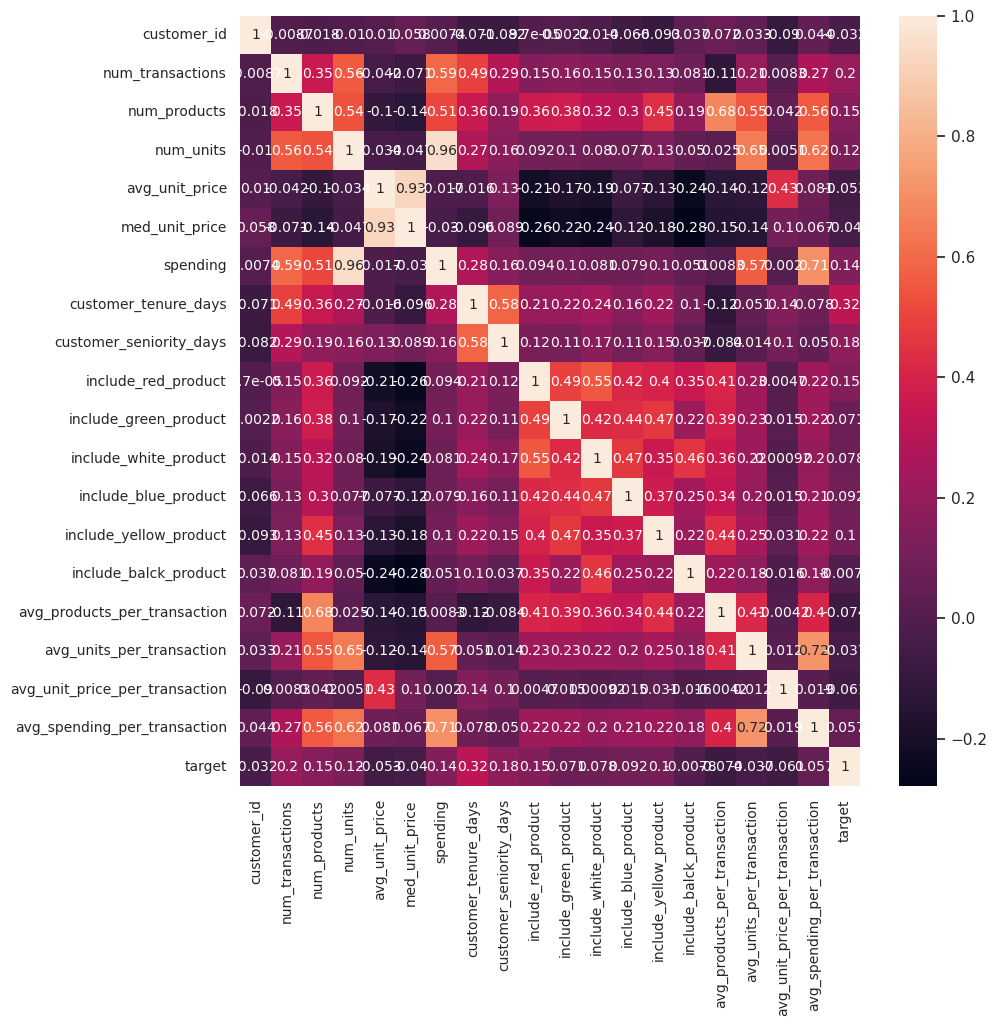

In [21]:
agg_df = agg_df.drop("color_unique", axis=1)
correlation = agg_df.corr()
plt.figure(figsize=(10, 10))
sns.heatmap(
    correlation,
    xticklabels=correlation.columns.values,
    yticklabels=correlation.columns.values,
    annot=True,
    annot_kws={"size": 10},
)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

In [22]:
# Variables with correlation >=0.98 dropped 
agg_df = agg_df.drop(
    [
        "avg_unit_price_per_transaction",
        "med_unit_price",
        "customer_tenure_days",
        "spending",
    ],
    axis=1,
)

---
## GENERALIZED LINEAR MODEL
---

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
train_df = agg_df.copy()
y = train_df["target"]
X = train_df.drop(columns=["customer_id", "target"])

We are going to use a logistic regression model and train it on our data X_train and y_train (70% of the data). We will later test it on X_test and y_test (30% of the data). 

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=18)

In [26]:
X_scaler = StandardScaler()
X_scaler.fit(X_train)
X_train = pd.DataFrame(X_scaler.transform(X_train), columns=X.columns)
X_test = pd.DataFrame(X_scaler.transform(X_test), columns=X.columns)

model = LogisticRegression(solver="liblinear")
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


Then, we define a function evaluate() to evaluate the model performance on the test sample. The evaluation metrics returned are :
- Accuracy, measuring the proportion of correctly classified instances out of all instances
- Precision, measuring the proportion of true positive predictions out of all positive predictions
- Recall, measuring the proportion of true positive predictions out of all actual positive instances
- And F1-score, the harmonic mean of precision and recall.

The closer these metrics are to 1, the better.

In [27]:
def evaluate(model_, X_test_, y_test_):
    prediction_test_ = model_.predict(X_test_)
    results = pd.DataFrame(
        {
            "Accuracy": [metrics.accuracy_score(y_test_, prediction_test_)],
            "Precision": [metrics.precision_score(y_test_, prediction_test_)],
            "Recall": [metrics.recall_score(y_test_, prediction_test_)],
            "F1_score": [metrics.f1_score(y_test_, prediction_test_)],
        }
    )
    return results

evaluate(model, X_test, y_test)

,Accuracy,Precision,Recall,F1_score
0,0.584416,0.526316,0.588235,0.555556


We can obtain the most important features by looking at the largest magnitude coefficients in the regression since we normalized the data via StandardScaler()

In [28]:
model.coef_[0]

array([ 0.60151483,  0.4862739 ,  0.11669873, -0.25543407,  0.21131471,
        0.28820151,  0.12143668, -0.00944552,  0.1053696 ,  0.05855209,
       -0.25039651, -0.50372435, -0.82722674,  0.45031666])

In [29]:
coefs = pd.DataFrame({"coef": model.coef_[0]}, index=X.columns)
coefs["coef_abs"] = coefs["coef"].abs()
coefs = coefs.sort_values(by="coef_abs", ascending=False)
coefs

,coef,coef_abs
avg_units_per_transaction,-0.827227,0.827227
num_transactions,0.601515,0.601515
avg_products_per_transaction,-0.503724,0.503724
num_products,0.486274,0.486274
avg_spending_per_transaction,0.450317,0.450317
include_red_product,0.288202,0.288202
avg_unit_price,-0.255434,0.255434
include_balck_product,-0.250397,0.250397
customer_seniority_days,0.211315,0.211315
include_green_product,0.121437,0.121437


In [30]:
print(f" {list(coefs.index[:5])} are the most important features")

 ['avg_units_per_transaction', 'num_transactions', 'avg_products_per_transaction', 'num_products', 'avg_spending_per_transaction'] are the most important features


---
## RANDOM FOREST
---

Let's try another model and show that it yields relatively the same results and conclusions.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz

In [32]:
model = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
evaluate(model, X_test, y_test)

,Accuracy,Precision,Recall,F1_score
0,0.649351,0.606061,0.588235,0.597015


---
HIGH POTENTIAL CUSTOMER DETECTION
---

Our objectif is now to create a model that detects high-potential customers in the database, meaning that identifies occasional customers which could purchase more frequently if activated.

In [34]:
# New data base and spending column defined
data_hp = data.copy()
data_hp["spending"] = data_hp["purchased_quantity"] * data_hp["unit_product_price"]

In [35]:
# Aggregated features by customer created
agg_df_hp = data_hp.groupby("customer_id", as_index=False).agg(
    {
        "transaction_id": pd.Series.nunique,  # number of transactions on the period per customer
        "product_id": pd.Series.nunique,  # number of unique products bought on the period per customer
        "purchased_quantity": "sum",  # units bought on the period per customer
        "unit_product_price": [
            "mean",
            "median",
        ],  # average unit price of the products bought on the period per customer
        "transaction_date": [
            "min",
            "max",
        ],  # date of first and most recent transaction on the period per customer
        "spending": "sum",  # spendings on the period per customer ,
    }
)

# Columns renamed
agg_df_hp.columns.to_flat_index()
agg_df_hp.columns = ["_".join(col) if col[1] else col[0] for col in agg_df_hp.columns]

agg_df_hp = agg_df_hp.rename(
    columns={
        "transaction_id_nunique": "num_transactions",
        "product_id_nunique": "num_products",
        "purchased_quantity_sum": "num_units",
        "unit_product_price_mean": "avg_unit_price",
        "unit_product_price_median": "med_unit_price",
        "transaction_date_min": "oldest_transaction",
        "transaction_date_max": "newest_transaction",
        "spending_sum": "spending",
    }
)

# Customer's seniority and tenure
agg_df_hp["customer_tenure_days"] = (
    (agg_df_hp["newest_transaction"] - agg_df_hp["oldest_transaction"]).dt.days
).fillna(0).astype(int)

# Customer earliest purchase from the client
agg_df_hp["customer_seniority_days"] = (
    (pd.to_datetime("2012-10-01") - agg_df_hp["oldest_transaction"]).dt.days
).fillna(0).astype(int)

agg_df_hp = agg_df_hp.drop(["newest_transaction", "oldest_transaction"], axis=1)
agg_df_hp.head()

,customer_id,num_transactions,num_products,num_units,avg_unit_price,med_unit_price,spending,customer_tenure_days,customer_seniority_days
0,0,1,73,631,8.289041,2.55,1757.55,0,0
1,1,1,4,20,6.075000,6.45,89.00,0,0
2,2,1,58,530,4.503793,2.95,1079.40,0,0
3,3,3,53,1591,3.201186,1.25,2811.43,0,-66
4,4,6,70,783,4.582857,2.10,1803.96,477,173


Based on the aggregated data, let's define already-high-value customers as those who spent more than 3500 euros on products over the full period. We can already define these as high-potential customers

In [36]:
agg_df_hp["high_potential"] = (agg_df_hp.spending >= 3500).map({True: 1, False: 0})
agg_df_hp.head(8)

,customer_id,num_transactions,num_products,num_units,avg_unit_price,med_unit_price,spending,customer_tenure_days,customer_seniority_days,high_potential
0,0,1,73,631,8.289041,2.55,1757.55,0,0,0
1,1,1,4,20,6.075000,6.45,89.00,0,0,0
2,2,1,58,530,4.503793,2.95,1079.40,0,0,0
3,3,3,53,1591,3.201186,1.25,2811.43,0,-66,0
4,4,6,70,783,4.582857,2.10,1803.96,477,173,0
5,5,5,57,1416,3.267403,1.45,1708.12,0,22,0
6,6,5,33,483,4.438696,1.55,806.27,0,0,0
7,7,4,82,1557,3.630722,2.10,3750.40,0,-152,1


Then, we must look at the high potential customers within now-low-value customers. To do so, let's use the clustering technique K-Means. The K-Means Clustering method groups the data into 2 clusters of similar customers(0 or 1).

In [37]:
from sklearn.cluster import KMeans
import pandas as pd

In [38]:
features = agg_df_hp[
    [
        "avg_unit_price",
        "num_transactions",
        "num_products",
        "num_units",
        "customer_tenure_days",
        "customer_seniority_days",
    ]
]

In [39]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [40]:
# Randomly take two of the already high potentiam customers as a seed to initialize the clusters centers

already_hp_customers = scaled_features[agg_df_hp["high_potential"] == 1]
np.random.seed(40)
model = KMeans(
    n_clusters=2,
    init=already_hp_customers[
        np.random.choice(already_hp_customers.shape[0], 2, replace=False)
    ],
    n_init=1,
)
model.fit(scaled_features)
clusters = model.predict(scaled_features)

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


2 high-potential individuals are randomly selected as seeds for the initialization of the KMeans model. Let's look at their value features.

In [41]:
print(model.init)

[[-0.05921494  1.29673313  1.70779064  0.14256627  1.03996678  0.39138507]
 [-0.06558892  1.29673313  2.36762357  0.24168612  0.33439904  0.87499947]]


To see if clustered are seperated in a meaningful way, we can plot customers in 2D, using as axes 2 of their features. Big black stars represent the two seeds, to vizualise the center of each cluster. 

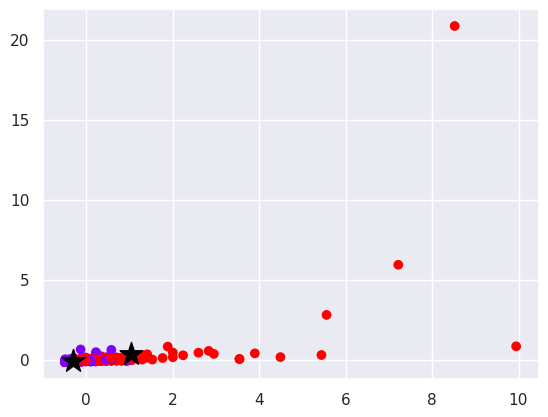

In [45]:
# Plot the clusters on 'num_transactions' and 'num_units' axes
plt.scatter(scaled_features[:, 1], scaled_features[:, 3], c=clusters, cmap="rainbow")
plt.scatter(
    model.cluster_centers_[:, 1],
    model.cluster_centers_[:, 3],
    c="black",
    marker="*",
    s=300,
)

In [46]:
agg_df_hp["cluster"] = clusters
agg_df_hp.loc[agg_df_hp.high_potential == 1, ["high_potential", "cluster"]].sum()

high_potential    45
cluster           39
dtype: int64

This code shows how many high-potential customers fall into cluster 1, helping us to evaluate if the clustering captures “good customers” well. Few already-high-potential customers were misidentified by the algorithm.

In [48]:
print(
    f"{ agg_df_hp.cluster.sum()/len(agg_df_hp)*100:.0f}% of the total customers were identified as potential high-value customer, \
i.e customers who could purchase more frequently if activated.) \
while only {45/len(agg_df_hp)*100 :.0f}% were already identified as high potential"
)

22% of the total customers were identified as potential high-value customer, i.e customers who could purchase more frequently if activated.) while only 9% were already identified as high potential


Let's now evaluate the performance of our clustering model, using two metrics :
- The Silhouette score, which measure how similar an object is to its cluster compared to other clusters, ranging from -1 to 1, with 1 indicating that the clusters are well-separated and that the objects are properly assigned to their clusters and -1 indicating that the clusters are not well-separated and the objects are assigned to the wrong clusters. A score of 0.5 or higher is considered good.
- And the Calinshi-Harabasz Index, a ratio between the between-clusters variance and the within-cluster variance. An index of 10 or higher is considered good.

In [51]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score

def evaluate_clustering(predicted_clusters, data):
    silhouette = silhouette_score(data, predicted_clusters)
    print("Silhouette score: {:.3f}".format(silhouette))
    calinski = calinski_harabasz_score(data, predicted_clusters)
    print("Calinski-Harabasz index: {:.3f}".format(calinski))

evaluate_clustering(clusters, agg_df_hp)

Silhouette score: 0.542
Calinski-Harabasz index: 19.221
